E-Commerce Sales Analysis
Business Questions
1. Which months generate the most and least revenue?
2. Which product categories perform best?
3. Who are the most valuable customers, and how much revenue comes from the top 10%?
4. What actions should the business take based on the analysis?
Data Source
This project uses generated (simulated) data for educational purposes. No real customer data is used.

1. Import libraries and generate the dataset

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

n_orders = 3000
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
categories = ["Electronics", "Fashion", "Home & Kitchen", "Beauty", "Sports"]
base_values = {"Electronics": 1200, "Fashion": 650, "Home & Kitchen": 850, "Beauty": 450, "Sports": 750}

customers = [f"CUST_{i:03d}" for i in range(1, 301)]
weights = np.random.pareto(2, len(customers)) + 1
weights = weights / weights.sum()

order_dates = np.random.choice(dates, n_orders)
order_categories = np.random.choice(categories, n_orders, p=[0.22, 0.25, 0.20, 0.18, 0.15])
order_customers = np.random.choice(customers, n_orders, p=weights)

revenue = [round(max(np.random.normal(base_values[c], base_values[c]*0.30), 100), 2)
           for c in order_categories]

df = pd.DataFrame({
    "order_id": [f"ORD_{i:05d}" for i in range(1, n_orders + 1)],
    "order_date": order_dates,
    "customer_id": order_customers,
    "category": order_categories,
    "revenue": revenue
})

# Small number of missing values for cleaning demonstration
df.loc[df.sample(5, random_state=1).index, "category"] = np.nan

print("Shape:", df.shape)
display(df.head())

Shape: (3000, 5)


,order_id,order_date,customer_id,category,revenue
0,ORD_00001,2025-12-31,CUST_294,Electronics,926.27
1,ORD_00002,2025-12-16,CUST_071,Sports,661.44
2,ORD_00003,2025-02-16,CUST_210,Fashion,724.57
3,ORD_00004,2025-12-21,CUST_222,Sports,454.76
4,ORD_00005,2025-11-07,CUST_187,Home & Kitchen,748.74


2. Inspect and clean the data
We check data types, missing values and duplicates. Rows with missing categories are removed because category analysis requires a known category, and only a small number of simulated rows are affected.

In [9]:
df.info()
print("\nMissing values:")
display(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.dropna(subset=["category"]).drop_duplicates().copy()
df["order_date"] = pd.to_datetime(df["order_date"])
print("\nShape after cleaning:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     3000 non-null   str           
 1   order_date   3000 non-null   datetime64[us]
 2   customer_id  3000 non-null   str           
 3   category     2995 non-null   str           
 4   revenue      3000 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 193.6 KB

Missing values:


order_id       0
order_date     0
customer_id    0
category       5
revenue        0
dtype: int64


Duplicate rows: 0

Shape after cleaning: (2995, 5)


3. Feature Engineering: Date Features

In [10]:
df["month"] = df["order_date"].dt.to_period("M")
df["weekday"] = df["order_date"].dt.day_name()
df["quarter"] = df["order_date"].dt.quarter
display(df.head())

,order_id,order_date,customer_id,category,revenue,month,weekday,quarter
0,ORD_00001,2025-12-31,CUST_294,Electronics,926.27,2025-12,Wednesday,4
1,ORD_00002,2025-12-16,CUST_071,Sports,661.44,2025-12,Tuesday,4
2,ORD_00003,2025-02-16,CUST_210,Fashion,724.57,2025-02,Sunday,1
3,ORD_00004,2025-12-21,CUST_222,Sports,454.76,2025-12,Sunday,4
4,ORD_00005,2025-11-07,CUST_187,Home & Kitchen,748.74,2025-11,Friday,4


4. Monthly Revenue Trend

,month,revenue,growth_pct
0,2025-01,209002.31,NaN
1,2025-02,169480.68,-18.91
2,2025-03,207170.13,22.24
3,2025-04,198405.60,-4.23
4,2025-05,211893.39,6.80
5,2025-06,202308.59,-4.52
6,2025-07,171218.72,-15.37
7,2025-08,209693.71,22.47
8,2025-09,194740.62,-7.13
9,2025-10,192373.37,-1.22


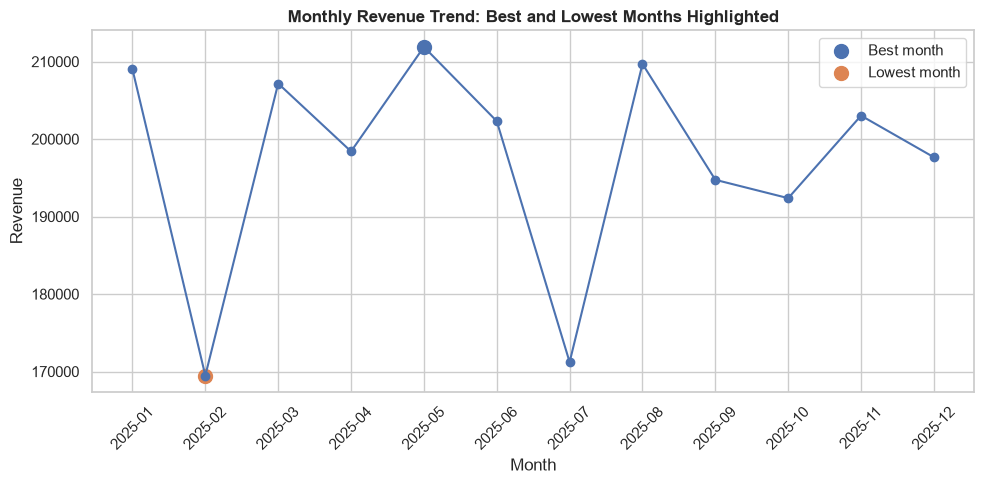

Best month: 2025-05 — ₹211,893.39
Lowest month: 2025-02 — ₹169,480.68


In [11]:
monthly_revenue = df.groupby("month")["revenue"].sum().reset_index()
monthly_revenue["month"] = monthly_revenue["month"].astype(str)
monthly_revenue["growth_pct"] = monthly_revenue["revenue"].pct_change() * 100

best_month = monthly_revenue.loc[monthly_revenue["revenue"].idxmax()]
worst_month = monthly_revenue.loc[monthly_revenue["revenue"].idxmin()]

display(monthly_revenue.round(2))

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue["month"], monthly_revenue["revenue"], marker="o")
plt.scatter(best_month["month"], best_month["revenue"], s=100, label="Best month")
plt.scatter(worst_month["month"], worst_month["revenue"], s=100, label="Lowest month")
plt.title("Monthly Revenue Trend: Best and Lowest Months Highlighted", weight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best month: {best_month['month']} — ₹{best_month['revenue']:,.2f}")
print(f"Lowest month: {worst_month['month']} — ₹{worst_month['revenue']:,.2f}")

5. Category Performance: GroupBy and Pivot Table

,total_revenue,average_order,order_count
category,,,
Electronics,786967.52,1203.31,654
Fashion,506549.33,646.93,783
Home & Kitchen,498923.33,852.86,585
Sports,333012.60,770.86,432
Beauty,241508.91,446.41,541


Monthly revenue by category:


category,Beauty,Electronics,Fashion,Home & Kitchen,Sports
month,,,,,
2025-01,23328.77,82145.77,43365.73,35111.87,25050.17
2025-02,19431.37,57813.99,37898.48,33212.90,21123.94
2025-03,19793.80,81060.46,37165.37,40602.53,28547.97
2025-04,20204.37,59184.40,44122.92,47257.40,27636.51
2025-05,23017.41,65590.30,46574.23,45345.10,31366.35
2025-06,20806.85,64956.25,46123.09,40287.66,30134.74
2025-07,14967.00,59519.04,31767.52,43284.46,21680.70
2025-08,22128.55,55644.98,41913.82,45240.49,44765.87
2025-09,17233.27,67169.78,42388.64,46692.17,21256.76


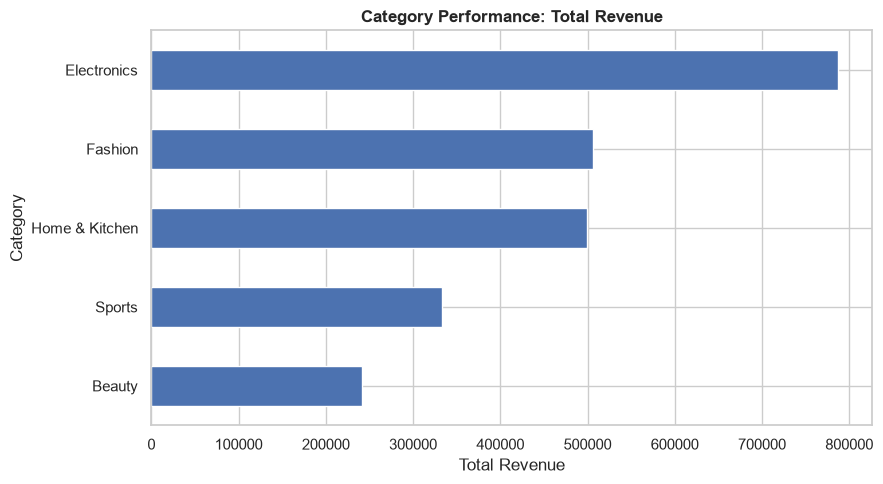

Best category: Electronics — ₹786,967.52


In [12]:
category_summary = (
    df.groupby("category")["revenue"]
    .agg(total_revenue="sum", average_order="mean", order_count="count")
    .sort_values("total_revenue", ascending=False)
)
display(category_summary.round(2))

category_pivot = pd.pivot_table(df, values="revenue", index="month",
                                columns="category", aggfunc="sum", fill_value=0)
print("Monthly revenue by category:")
display(category_pivot.round(2))

category_summary["total_revenue"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Category Performance: Total Revenue", weight="bold")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

best_category = category_summary.index[0]
best_category_revenue = category_summary.iloc[0]["total_revenue"]
print(f"Best category: {best_category} — ₹{best_category_revenue:,.2f}")

6. Most Valuable Customers and the Pareto Idea

,customer_id,total_spend
0,CUST_262,40627.83
1,CUST_155,39284.82
2,CUST_070,36207.45
3,CUST_249,30756.00
4,CUST_140,30582.56
5,CUST_051,28646.83
6,CUST_141,26829.95
7,CUST_012,23824.17
8,CUST_035,22609.81
9,CUST_056,22000.09


Top 10% customers: 30
Revenue share from top 10%: 27.45%


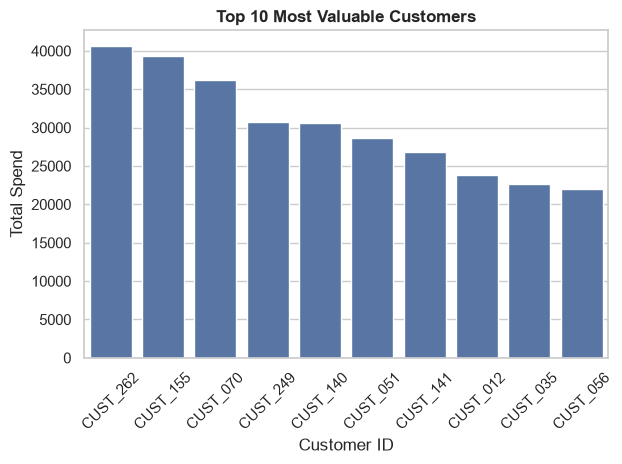

In [13]:
customer_spend = (
    df.groupby("customer_id")["revenue"].sum()
    .sort_values(ascending=False).reset_index(name="total_spend")
)

top_n = max(1, int(np.ceil(len(customer_spend) * 0.10)))
top_customers = customer_spend.head(top_n)
total_revenue = customer_spend["total_spend"].sum()
top_revenue = top_customers["total_spend"].sum()
top_share = (top_revenue / total_revenue) * 100

display(customer_spend.head(10).round(2))
print(f"Top 10% customers: {top_n}")
print(f"Revenue share from top 10%: {top_share:.2f}%")

sns.barplot(data=customer_spend.head(10), x="customer_id", y="total_spend")
plt.title("Top 10 Most Valuable Customers", weight="bold")
plt.xlabel("Customer ID")
plt.ylabel("Total Spend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

7. Actionable Business Recommendations

In [14]:
print("1. CATEGORY ACTION")
print(f"Prioritise {best_category}, the highest-revenue category at ₹{best_category_revenue:,.0f}.")

print("\n2. CUSTOMER ACTION")
print(f"Test a loyalty offer for the top {top_n} customers (top 10%), who contribute {top_share:.1f}% of revenue.")

print("\n3. TREND ACTION")
print(f"Study what worked in {best_month['month']} (best month) and test those ideas during weaker periods such as {worst_month['month']}.")

1. CATEGORY ACTION
Prioritise Electronics, the highest-revenue category at ₹786,968.

2. CUSTOMER ACTION
Test a loyalty offer for the top 30 customers (top 10%), who contribute 27.4% of revenue.

3. TREND ACTION
Study what worked in 2025-05 (best month) and test those ideas during weaker periods such as 2025-02.


Conclusion
This project used generated e-commerce sales data to analyse monthly revenue trends, category performance and customer value.

The analysis used feature engineering, groupby(), pivot tables and Pareto-style customer analysis. The recommendations are based on calculated results from the dataset.